# Figure 5


In [2]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_pupilchoicehistory_accept_data,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper function

In [27]:
def plot_accept_pupil_scatter(ax, x, y, show_ylabel_text=None):
    """Scatter of mean acceptance rate (x) vs. a pupil beta contrast
    (y), with a chance-level vertical line (x=0.5, red/blue tinted
    halves), a zero horizontal line, a linear best-fit line, and the
    Pearson r/p/n annotated at the top-left."""
    ax.axvspan(0.5, 1, color="red", alpha=0.08, zorder=0)
    ax.axvspan(0, 0.5, color="blue", alpha=0.08, zorder=0)

    ax.axhline(0, color="black", linewidth=1, zorder=1)
    ax.axvline(0.5, color="black", linewidth=1, zorder=1)

    ax.scatter(x, y, color="black", s=90, alpha=0.85,
               edgecolor="black", linewidth=0.5, zorder=3)

    slope, intercept = np.polyfit(x, y, 1)
    x_fit = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_fit, slope * x_fit + intercept, color="black",
           linewidth=2, zorder=2)

    r, p = stats.pearsonr(x, y)
    p_text = f"p = {p:.3g}" if p >= 0.001 else "p < 0.001"
    ax.text(0.95, 0.99, f"Pearson r = {r:.2f}\n{p_text}\nn = {len(x)}", transform=ax.transAxes,
            ha="right", va="top", fontsize=14)
    print("Dataset:", ax.get_title())
    print(f"Pearson r = {r:.2f}, p = {p:.3g}, n = {len(x)}")

    ax.set_xlim(0, 1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if show_ylabel_text is not None:
        ax.set_ylabel(show_ylabel_text)

### 1x3 figure: mean acceptance vs. pupil accept/reject contrast
y = mean(AA, RA) - mean(AR, RR).

Dataset: 
Pearson r = -0.60, p = 0.000264, n = 32
Dataset: 
Pearson r = -0.68, p = 3.91e-05, n = 30
Dataset: 
Pearson r = -0.33, p = 0.00826, n = 62


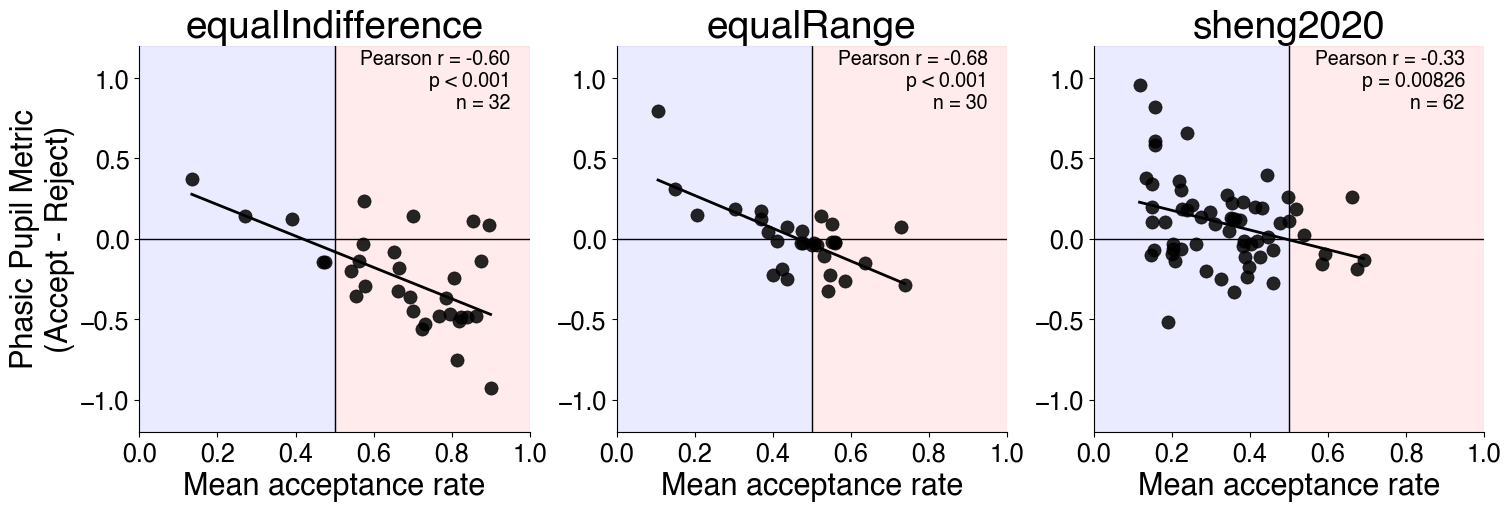

In [29]:
accept_data = load_pupilchoicehistory_accept_data()

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5),
                         layout="constrained")

for col, ds in enumerate(DATASETS):
    ds_data = accept_data[accept_data["dataset"] == ds]
    x = ds_data["mean_accept_rate"].values

    mean_accept_pupil = (ds_data["pupilAA"] + ds_data["pupilRA"]) / 2
    mean_reject_pupil = (ds_data["pupilAR"] + ds_data["pupilRR"]) / 2
    y = (mean_accept_pupil - mean_reject_pupil).values

    plot_accept_pupil_scatter(
        axes[col], x, y,
        show_ylabel_text="Phasic Pupil Metric\n(Accept - Reject)" if col == 0 else None,
    )
    axes[col].set_title(DATASET_LABELS.get(ds, ds))
    axes[col].set_xlabel("Mean acceptance rate")
    axes[col].set_ylim(-1.2, 1.2)

# Row label, placed just outside the top-left corner of the leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
# axes[0].text(-0.25, 1.1, "A.", transform=axes[0].transAxes,
#             fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure5.svg", dpi=300, bbox_inches="tight")
plt.show()